In [3]:
!pip install -q pennylane==0.45.1

import time
import json
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

n_qubits = 8
n_features = 32
torch.manual_seed(0)

In [4]:
data_dir = "/kaggle/input/datasets/malakkhaled202300369/nic-feature-dataset/prep"

angles, meta = {}, {}
for split in ["train", "val"]:
    angles[split] = np.load(f"{data_dir}/ffpp_{split}_angles32.npy").astype(np.float32)
    meta[split] = pd.read_csv(f"{data_dir}/ffpp_{split}_rows.csv")

is_inner = np.load(f"{data_dir}/ffpp_train_is_inner.npy").astype(bool)
fit_idx = np.where(is_inner)[0]
search_idx = np.where(~is_inner)[0]

x_train, x_val = angles["train"], angles["val"]
y_train = meta["train"]["label"].to_numpy().astype(np.float32)
y_val = meta["val"]["label"].to_numpy().astype(np.float32)

print("train", x_train.shape, "val", x_val.shape)
print("inner fitness frames:", len(fit_idx), " search-train frames:", len(search_idx))

train (46076, 32) val (22396, 32)
inner fitness frames: 6912  search-train frames: 39164


In [5]:
def build_circuit(g):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        for i in range(n_qubits):
            if g["enc"] == 0:
                qml.RX(x[:, i], wires=i)
            elif g["enc"] == 1:
                qml.RY(x[:, i], wires=i)
            else:
                qml.Hadamard(wires=i)
                qml.RZ(x[:, i], wires=i)
        for layer in range(g["depth"]):
            for i in range(n_qubits):
                if g["rot"][layer] == 0:
                    qml.RY(w[layer, i, 0], wires=i)
                elif g["rot"][layer] == 1:
                    qml.RX(w[layer, i, 0], wires=i)
                    qml.RY(w[layer, i, 1], wires=i)
                else:
                    qml.Rot(w[layer, i, 0], w[layer, i, 1], w[layer, i, 2], wires=i)
            if g["ent"][layer] == 1:
                for i in range(n_qubits - 1):
                    qml.CNOT(wires=[i, i + 1])
            elif g["ent"][layer] == 2:
                for i in range(n_qubits):
                    qml.CNOT(wires=[i, (i + 1) % n_qubits])
            elif g["ent"][layer] == 3:
                for i in range(n_qubits):
                    qml.CZ(wires=[i, (i + 1) % n_qubits])
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

    return circuit


class QuantumClassifier(torch.nn.Module):
    def __init__(self, g):
        super().__init__()
        self.circuit = build_circuit(g)
        self.rot = torch.nn.Parameter(0.1 * torch.randn(g["depth"], n_qubits, 3))
        self.readout = torch.nn.Linear(n_qubits, 1)

    def forward(self, x):
        out = torch.stack(self.circuit(x, self.rot), dim=1).float()
        return self.readout(out).squeeze(1)


def train(model, x, y, lr, epochs, batch_size, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.as_tensor(x, dtype=torch.float32)
    y = torch.as_tensor(y, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    for epoch in range(epochs):
        order = torch.randperm(len(x), generator=g)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            opt.zero_grad()
            loss_fn(model(x[idx]), y[idx]).backward()
            opt.step()


def predict(model, x, batch_size=1000):
    out = []
    with torch.no_grad():
        for s in range(0, len(x), batch_size):
            xb = torch.as_tensor(x[s:s + batch_size], dtype=torch.float32)
            out.append(torch.sigmoid(model(xb)))
    return torch.cat(out).numpy()


def video_level(prob, y, info):
    df = info[["method", "video_id"]].copy()
    df["p"] = prob
    df["y"] = y
    g = df.groupby(["method", "video_id"]).agg(p=("p", "mean"), y=("y", "first"))
    return g["p"].to_numpy(), g["y"].to_numpy()


def bootstrap_ci(p, y, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    aucs = []
    while len(aucs) < n:
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        aucs.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(aucs, [2.5, 97.5])

In [6]:
# the same 2000 search-train frames every time (1000 real, 1000 fake)
st = meta["train"].iloc[search_idx].copy()
st["row"] = search_idx
real_pick = st[st["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
fake_pick = st[st["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
rng = np.random.default_rng(0)
sub = np.concatenate([rng.choice(real_pick, 1000, replace=False), rng.choice(fake_pick, 1000, replace=False)])

x_sub, y_sub = x_train[sub], y_train[sub]
x_fit, y_fit = x_train[fit_idx], y_train[fit_idx]

gate_penalty = 0.0006
gates_per_entangler = [0, n_qubits - 1, n_qubits, n_qubits]   # none, chain, cnot ring, cz ring


def n_two_qubit(g):
    return sum(gates_per_entangler[e] for e in g["ent"][:g["depth"]])


def fitness(g):
    cols = g["mask"]
    torch.manual_seed(0)
    model = QuantumClassifier(g)
    train(model, x_sub[:, cols], y_sub, lr=0.03, epochs=6, batch_size=100)
    auc = roc_auc_score(y_fit, predict(model, x_fit[:, cols]))
    return auc - gate_penalty * n_two_qubit(g)


# a genome only depends on the layers it uses, so the key ignores the unused ones
def key(g):
    d = g["depth"]
    return (tuple(g["mask"]), g["enc"], d, tuple(g["rot"][:d]), tuple(g["ent"][:d]))


enc_names = ["rx", "ry", "h+rz"]
rot_names = ["ry", "rx+ry", "rot"]
ent_names = ["none", "chain", "cnot ring", "cz ring"]


def describe(g):
    layers = ", ".join(f"{rot_names[g['rot'][i]]}/{ent_names[g['ent'][i]]}" for i in range(g["depth"]))
    return f"features {g['mask']} | enc {enc_names[g['enc']]} | depth {g['depth']} | {layers}"

In [7]:
def random_genome(rng):
    return {
        "mask": sorted(rng.choice(n_features, n_qubits, replace=False).tolist()),
        "enc": int(rng.integers(3)),
        "depth": int(rng.integers(1, 5)),
        "rot": rng.integers(3, size=4).tolist(),
        "ent": rng.integers(4, size=4).tolist(),
    }


def crossover(a, b, rng):
    # features both parents have are kept, the rest are drawn from the features only one parent has
    shared = set(a["mask"]) & set(b["mask"])
    rest = list(set(a["mask"]) ^ set(b["mask"]))
    extra = rng.choice(rest, n_qubits - len(shared), replace=False).tolist() if rest else []
    pick = lambda x, y: x if rng.random() < 0.5 else y
    return {
        "mask": sorted(shared | set(extra)),
        "enc": pick(a["enc"], b["enc"]),
        "depth": pick(a["depth"], b["depth"]),
        "rot": [pick(a["rot"][i], b["rot"][i]) for i in range(4)],
        "ent": [pick(a["ent"][i], b["ent"][i]) for i in range(4)],
    }


def mutate(g, rng, rate=0.15):
    mask = list(g["mask"])
    for i in range(n_qubits):
        if rng.random() < rate:
            free = [f for f in range(n_features) if f not in mask]
            mask[i] = int(rng.choice(free))
    new = {"mask": sorted(mask), "enc": g["enc"], "depth": g["depth"],
           "rot": list(g["rot"]), "ent": list(g["ent"])}
    if rng.random() < rate:
        new["enc"] = int(rng.integers(3))
    if rng.random() < rate:
        new["depth"] = int(rng.integers(1, 5))
    for i in range(4):
        if rng.random() < rate:
            new["rot"][i] = int(rng.integers(3))
        if rng.random() < rate:
            new["ent"][i] = int(rng.integers(4))
    return new


def tournament(pop, rng, k=3):
    picks = rng.choice(len(pop), k, replace=False)
    return max((pop[i] for i in picks), key=lambda p: p[0])[1]


# trains a genome only if it is new and the budget is not used up
def score(g, pool, curve, budget):
    k = key(g)
    if k not in pool:
        if len(pool) >= budget:
            return None
        pool[k] = (fitness(g), g)
        curve.append(pool[k][0])
        if len(curve) % 10 == 0:
            print(f"  {len(curve)} circuits trained, best fitness {max(curve):.4f}")
    return pool[k][0]


def run_random(seed, budget):
    rng = np.random.default_rng(seed + 100)
    pool, curve = {}, []
    while len(pool) < budget:
        score(random_genome(rng), pool, curve, budget)
    return pool, curve


def run_ga(seed, budget, pop_size=20):
    rng = np.random.default_rng(seed)
    pool, curve = {}, []
    pop = []
    while len(pop) < pop_size:
        g = random_genome(rng)
        pop.append((score(g, pool, curve, budget), g))
    while len(pool) < budget:
        children = []
        for _ in range(pop_size):
            child = mutate(crossover(tournament(pop, rng), tournament(pop, rng), rng), rng)
            f = score(child, pool, curve, budget)
            if f is None:
                break
            children.append((f, child))
        pop = sorted(pop + children, key=lambda p: p[0], reverse=True)[:pop_size]
    return pool, curve

In [8]:
budget = 100        # distinct circuits per run. the full project plan uses 600
seeds = [0]         # add more seeds for more independent runs

runs = {"ga": [], "random": []}
for seed in seeds:
    for name, search in [("ga", run_ga), ("random", run_random)]:
        print(f"--- {name}, seed {seed}")
        t0 = time.time()
        pool, curve = search(seed, budget)
        runs[name].append((pool, curve))
        print(f"  done in {(time.time() - t0) / 60:.1f} min, best fitness {max(curve):.4f}")

--- ga, seed 0
  10 circuits trained, best fitness 0.6546
  20 circuits trained, best fitness 0.6609
  30 circuits trained, best fitness 0.6717
  40 circuits trained, best fitness 0.6717
  50 circuits trained, best fitness 0.6717
  60 circuits trained, best fitness 0.6717
  70 circuits trained, best fitness 0.6717
  80 circuits trained, best fitness 0.6771
  90 circuits trained, best fitness 0.6771
  100 circuits trained, best fitness 0.6871
  done in 21.9 min, best fitness 0.6871
--- random, seed 0
  10 circuits trained, best fitness 0.6684
  20 circuits trained, best fitness 0.6684
  30 circuits trained, best fitness 0.6684
  40 circuits trained, best fitness 0.6684
  50 circuits trained, best fitness 0.6736
  60 circuits trained, best fitness 0.6736
  70 circuits trained, best fitness 0.6736
  80 circuits trained, best fitness 0.6736
  90 circuits trained, best fitness 0.6736
  100 circuits trained, best fitness 0.6736
  done in 18.4 min, best fitness 0.6736


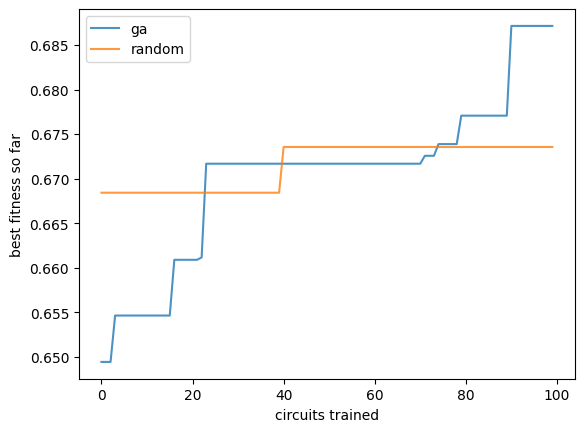

ga best fitness per run: [0.6871]
random best fitness per run: [0.6736]


In [9]:
for name, color in [("ga", "tab:blue"), ("random", "tab:orange")]:
    for i, (pool, curve) in enumerate(runs[name]):
        plt.plot(np.maximum.accumulate(curve), color=color, alpha=0.8, label=name if i == 0 else None)
plt.xlabel("circuits trained")
plt.ylabel("best fitness so far")
plt.legend()
plt.show()

for name in runs:
    best = [max(curve) for pool, curve in runs[name]]
    print(name, "best fitness per run:", np.round(best, 4))

In [10]:
# the 3 best circuits of each run are retrained on all of ff++ train and scored on validation
top_k = 3
rows = []
for name in runs:
    for seed, (pool, curve) in zip(seeds, runs[name]):
        best = sorted(pool.values(), key=lambda p: p[0], reverse=True)[:top_k]
        for rank, (fit, g) in enumerate(best, 1):
            cols = g["mask"]
            torch.manual_seed(0)
            model = QuantumClassifier(g)
            train(model, x_train[:, cols], y_train, lr=0.01, epochs=5, batch_size=256)
            pv, yv = video_level(predict(model, x_val[:, cols]), y_val, meta["val"])
            lo, hi = bootstrap_ci(pv, yv)
            rows.append({"method": name, "seed": seed, "rank": rank, "fitness": round(fit, 3),
                         "val video auc": round(roc_auc_score(yv, pv), 3),
                         "95% interval": f"{lo:.3f} to {hi:.3f}", "circuit": describe(g)})
            print(name, seed, rank, rows[-1]["val video auc"])

final = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
print(final.to_string(index=False))

ga 0 1 0.689
ga 0 2 0.666
ga 0 3 0.662
random 0 1 0.652
random 0 2 0.671
random 0 3 0.683
method  seed  rank  fitness  val video auc   95% interval                                                                                              circuit
    ga     0     1    0.687          0.689 0.641 to 0.734          features [8, 10, 16, 17, 21, 22, 24, 25] | enc rx | depth 3 | ry/none, ry/none, rot/cz ring
    ga     0     2    0.677          0.666 0.621 to 0.712 features [8, 9, 10, 14, 17, 20, 22, 25] | enc rx | depth 4 | ry/none, ry/none, rot/chain, rx+ry/none
    ga     0     3    0.677          0.662 0.617 to 0.711                                   features [1, 7, 8, 9, 14, 17, 20, 25] | enc rx | depth 1 | ry/none
random     0     1    0.674          0.652 0.604 to 0.699                                 features [2, 5, 8, 9, 10, 13, 15, 24] | enc h+rz | depth 1 | ry/none
random     0     2    0.671          0.671 0.623 to 0.715                                  features [4, 6, 8, 14, 1

In [13]:
table = final.copy()

parts = table["circuit"].str.split(" \\| ", expand=True)
table["features"] = parts[0].str.replace("features [", "", regex=False).str.replace("]", "", regex=False).str.replace(",", "")
table["encoding"] = parts[1].str.replace("enc ", "", regex=False)
table["depth"] = parts[2].str.replace("depth ", "", regex=False).astype(int)
table["layers"] = parts[3].str.replace(", ", "; ", regex=False)

ci = table["95% interval"].str.split(" to ", expand=True).astype(float)
table["ci_low"] = ci[0]
table["ci_high"] = ci[1]

table = table.rename(columns={"val video auc": "val_auc"})
table = table[["method", "seed", "rank", "fitness", "val_auc", "ci_low", "ci_high",
               "features", "encoding", "depth", "layers"]]

table.to_csv("/kaggle/working/search_results.csv", index=False)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)
table

,method,seed,rank,fitness,val_auc,ci_low,ci_high,features,encoding,depth,layers
0,ga,0,1,0.687,0.689,0.641,0.734,8 10 16 17 21 22 24 25,rx,3,ry/none; ry/none; rot/cz ring
1,ga,0,2,0.677,0.666,0.621,0.712,8 9 10 14 17 20 22 25,rx,4,ry/none; ry/none; rot/chain; rx+ry/none
2,ga,0,3,0.677,0.662,0.617,0.711,1 7 8 9 14 17 20 25,rx,1,ry/none
3,random,0,1,0.674,0.652,0.604,0.699,2 5 8 9 10 13 15 24,h+rz,1,ry/none
4,random,0,2,0.671,0.671,0.623,0.715,4 6 8 14 15 17 20 28,rx,1,ry/none
5,random,0,3,0.668,0.683,0.635,0.727,1 2 3 8 13 16 19 21,h+rz,1,rot/cz ring


In [11]:
log = {
    "budget": budget,
    "seeds": seeds,
    "curves": {name: [curve for pool, curve in runs[name]] for name in runs},
    "final": final.to_dict(orient="records"),
}
with open("/kaggle/working/search_log.json", "w") as f:
    json.dump(log, f, indent=2)
final.to_csv("/kaggle/working/search_final.csv", index=False)